# 13 · A deep field in HST and DESI, and what WCC sees of it

A real 3' x 3' patch of the **GOODS-South field, around the Hubble Ultra Deep Field**, in HST and in DESI, and how a WCC exposure of it looks in the three Lazuli filters
**g, r and i**, depending on what goes into the simulation.

The field is chosen for its filters. The original GOODS ACS survey observed F435W (B), F606W (V) and F775W (i), the closest HST match to the WCC `zwo:g`, `zwo:r` and `zwo:i`
(the CANDELS mosaics of COSMOS and EGS have no blue ACS band), and the Legacy Surveys DR10 has g, r and i there.

| Part | Content | Data |
|---|---|---|
| **1** | **The field**: a 3' x 3' view in HST and in DESI, with colour images built by hand | GOODS ACS F435W, F606W, F775W; Legacy Surveys DR10 g, r, i |
| **2** | **What WCC sees**: a 52" x 35" frame simulated in WCC g, r and i, from the HST images and from the DESI images, with zooms on individual galaxies | the same data |

The code lives in `scripts/` (`goods_cutout.py`, `candels_cutout.py`, `legacysurvey_galaxy_mock.py`, `hst_catalog_mock.py`); this notebook calls it. The first run downloads data
(about 0.6 GB of HST rows for the 3' view, plus a few small cutouts and the Tractor catalog; about a minute here, depending on the archive's speed, and Data Lab can be slow, in which case the
Tractor catalog comes from the legacysurvey.org viewer instead). Everything is cached in `ls_cache/` afterwards.

In [1]:
import os, sys, time, warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from astropy.nddata import Cutout2D
from astropy.coordinates import SkyCoord
from astropy.stats import sigma_clipped_stats
from astropy.visualization import make_lupton_rgb
from reproject import reproject_interp
from scipy.ndimage import gaussian_filter

sys.path.insert(0, os.path.abspath("../scripts"))
import goods_cutout as gc
import hst_catalog_mock as hcm
import legacysurvey_galaxy_mock as lsm
from wcc_sim import ImageComponent, detector_frame, empty_catalog, simulate_field
from wcc_sim.starflux import REF_MAG, rate_for_ab

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
# noisy images compress far better as JPEG than PNG (keeps the saved notebook small)
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}

## Setup

The WCC detector as a 52" x 35" subarray, centred on a point of GOODS-South 22" south of the Ultra Deep Field's centre, which keeps a 3' x 3' view inside one ACS mosaic tile.

In [2]:
FIELD = "goods-s"
RA, DEC = 53.1625, -27.79755             # the centre of the 3' view and of the WCC frame
SENSORFILTER = "zwo:r"                   # the detector geometry; all three filters share it
SHAPE = (2048, 3072)                     # WCC subarray (ny, nx): 51.8" x 34.5"
CACHE = "ls_cache"

frame = detector_frame(SENSORFILTER, (RA, DEC), shape=SHAPE)
ny, nx = frame.shape
pix = frame.plate_scale_mas / 1000.0
width, height = nx * pix, ny * pix
half_diag = 0.5 * np.hypot(nx, ny) * pix
print(f"frame {nx} x {ny} px = {width:.1f}\" x {height:.1f}\" at {frame.plate_scale_mas:.2f} mas/px")

def regrid(data, wcs, out_wcs, shape):
    """Bilinear reprojection of an image onto another WCS (NaN outside the image)."""
    out, _ = reproject_interp((data, wcs), out_wcs, shape_out=shape, order="bilinear")
    return out

def nanomaggies(data, zp, pixel):
    return data * 10.0 ** (0.4 * (22.5 - zp)) / pixel**2         # an AB flux density per arcsec^2

frame 3072 x 2048 px = 51.8" x 34.5" at 16.87 mas/px


In [3]:
# colour-stretch settings (the white point, in noise-sigmas of the summed intensity; see Part 1)
STRETCH_HST, STRETCH_DESI = 6.0, 15.0
STRETCH_WCC_HST, STRETCH_WCC_DESI = 8.0, 12.0

# Part 1 · The field: a 3' x 3' view of GOODS-South in HST and DESI

The same 3' x 3' field in two surveys:

* **HST (GOODS ACS)**: F435W, F606W and F775W at 30 mas/pixel, with a net exposure of about 7200, 5450 and 7000 s. Sharp and deep, over a small part of the sky.
* **DESI Legacy Surveys DR10**: g, r and i from DECam at about 1" seeing, over most of the southern sky.

Every band is converted to nanomaggies per arcsec^2 (an AB flux density; the HST pixel values are in e-/s and use the zero points of the GOODS documentation) and put on one
north-up 60 mas pixel grid (the ACS bands are binned 2 x 2).

In [4]:
FOV = 180.0                                      # arcsec: 3' x 3'

def bin_wcs(wcs, n):
    """WCS of an image binned n x n."""
    out = wcs.deepcopy()
    out.wcs.crpix = (wcs.wcs.crpix - 0.5) / n + 0.5
    if wcs.wcs.has_cd():
        out.wcs.cd = wcs.wcs.cd * n
    else:
        out.wcs.cdelt = wcs.wcs.cdelt * n
    return out

t0 = time.perf_counter()
hst_cut = {band: gc.fetch_goods_cutout(RA, DEC, FOV, FOV, band, field=FIELD, cache_dir=CACHE)       # (data, wcs, zero point, header), 30 mas
           for band in ("f435w", "f606w", "f775w")}
print(f"HST cutouts {hst_cut['f606w'][0].shape} in {time.perf_counter() - t0:.0f} s (cached reads are instant)")

grid_wcs = bin_wcs(hst_cut["f606w"][1], 2)                       # the 60 mas north-up grid of every band below
grid_shape = (hst_cut["f606w"][0].shape[0] // 2, hst_cut["f606w"][0].shape[1] // 2)
bin2 = lambda a: a[:grid_shape[0] * 2, :grid_shape[1] * 2].reshape(grid_shape[0], 2, grid_shape[1], 2).mean(axis=(1, 3))
hst_bands = {band: bin2(nanomaggies(data, zp, 0.030)) for band, (data, wcs, zp, _) in hst_cut.items()}

t0 = time.perf_counter()
desi_bands = {}
for band in "gri":
    data, wcs = lsm.fetch_ls_cutout(RA, DEC, FOV, layer="ls-dr10", band=band, npix=700)        # 0.26"/px
    desi_bands[band] = regrid(data / (FOV / 700) ** 2, wcs, grid_wcs, grid_shape)
print(f"DESI g, r, i cutouts in {time.perf_counter() - t0:.0f} s")
print("data in the whole grid:", {k: f"{np.mean(np.isfinite(v)):.0%}" for k, v in {**hst_bands, **desi_bands}.items()})

HST cutouts (6000, 6000) in 50 s (cached reads are instant)


DESI g, r, i cutouts in 22 s
data in the whole grid: {'f435w': '100%', 'f606w': '100%', 'f775w': '100%', 'g': '100%', 'r': '100%', 'i': '100%'}


## Making a colour image yourself

A colour image is three single-band images assigned to red, green and blue, with one common brightness stretch so that the *colours* are kept. The recipe uses the Lupton et al.
(2004) asinh stretch, `astropy.visualization.make_lupton_rgb`, as in the PHANGS notebook, with two additions that make a deep field of faint galaxies look right:

1. **Subtract the sky** of each band (its median).
2. **Balance the colours.** Equal weights in AB flux density do not give natural colours, because the sky and most galaxies are not equally bright in all bands. The bands are
   therefore scaled so that the median *detected* pixel is neutral grey; bluer than typical objects then show blue and redder ones red, as in the Hubble Deep Field.
3. **Set the stretch from the noise, not from the brightest pixels.** The PHANGS notebook puts the white point at the 99.5th percentile of one band, which suits big bright
   galaxies; in a field of faint compact ones the bright stars would then set the scale and the galaxies vanish. Here the white point is `stretch_sigma` times the noise of the
   summed intensity, and the black level (`minimum`) is one noise-sigma, so sky noise stays black.
4. `make_lupton_rgb(R, G, B, Q, stretch, minimum)` stretches the *summed intensity* with an asinh curve (linear for faint pixels, logarithmic for bright ones) and scales the three
   channels by the same factor, so a pixel's colour ratios survive the stretch. `Q` sets how soft the transition is.

The wavelength order sets the colours: the longest band goes to red, the shortest to blue (HST: F775W, F606W, F435W; DESI: i, r, g).

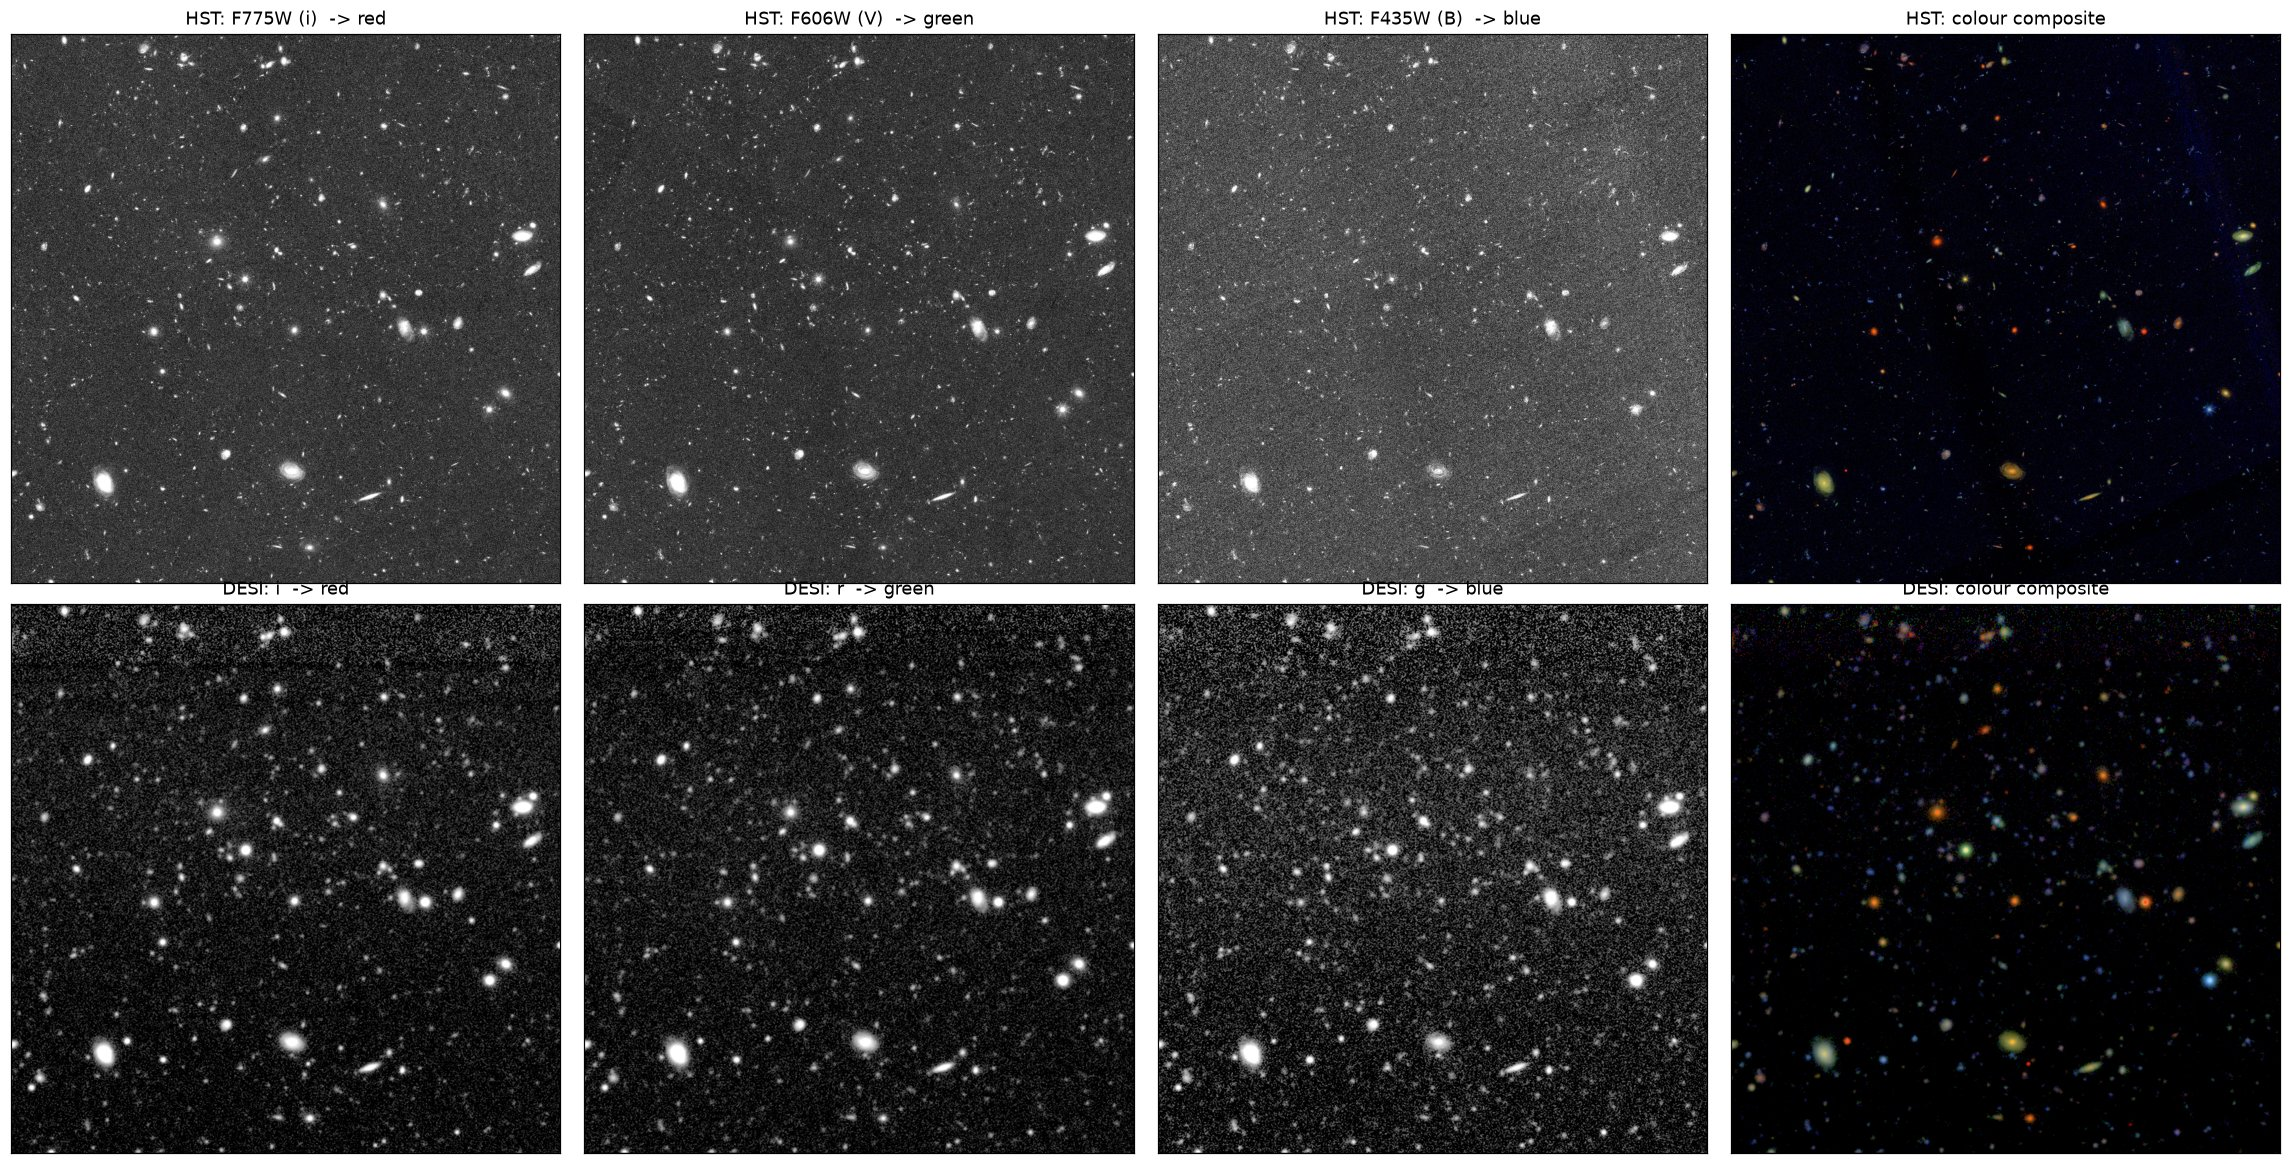

In [5]:
def colour_image(red, green, blue, stretch_sigma=8.0, Q=10.0, floor_sigma=1.0, detect_sigma=5.0):
    chans = [np.nan_to_num(a - np.nanmedian(a)) for a in (red, green, blue)]               # 1. sky-subtract
    noise = [sigma_clipped_stats(c, sigma=3)[2] for c in chans]
    detected = sum(c / s for c, s in zip(chans, noise)) > detect_sigma * np.sqrt(3)        # 2. colour balance: the median detected pixel
    flux = [np.median(c[detected]) for c in chans]                                         #    becomes neutral, with the middle band as the reference
    chans = [c * flux[1] / f for c, f in zip(chans, flux)]
    sigma_I = sigma_clipped_stats(sum(chans) / 3, sigma=3)[2]                              # noise of the summed intensity
    return make_lupton_rgb(*chans, Q=Q, stretch=stretch_sigma * sigma_I,                   # 3. + 4. noise-based white point, asinh stretch
                           minimum=floor_sigma * sigma_I)

def own_stretch(img, soft=20.0, hi_pct=99.7):
    good = np.isfinite(img)
    med, sig = sigma_clipped_stats(img[good], sigma=3)[1:]
    lo, hi = med - 0.5 * sig, np.nanpercentile(img[good], hi_pct)
    return np.clip(np.arcsinh((np.nan_to_num(img, nan=lo) - lo) / (hi - lo) * soft) / np.arcsinh(soft), 0, 1)

hst_rgb = colour_image(hst_bands["f775w"], hst_bands["f606w"], hst_bands["f435w"], stretch_sigma=STRETCH_HST)
desi_rgb = colour_image(desi_bands["i"], desi_bands["r"], desi_bands["g"], stretch_sigma=STRETCH_DESI)      # DESI's colours are noisier: a gentler stretch

# the ingredients of each composite (each band on its own stretch), then the result
half = FOV / 2
fig, axes = plt.subplots(2, 4, figsize=(21, 10.6))
rows = (("HST", (hst_bands["f775w"], "F775W (i)  -> red"), (hst_bands["f606w"], "F606W (V)  -> green"), (hst_bands["f435w"], "F435W (B)  -> blue"), hst_rgb),
        ("DESI", (desi_bands["i"], "i  -> red"), (desi_bands["r"], "r  -> green"), (desi_bands["g"], "g  -> blue"), desi_rgb))
for row, (name, *bands, rgb) in zip(axes, rows):
    for ax, (img, label) in zip(row[:3], bands):
        ax.imshow(own_stretch(img), origin="lower", cmap="gray", vmin=0, vmax=1, extent=(-half, half, -half, half))
        ax.set_title(f"{name}: {label}")
    row[3].imshow(rgb, origin="lower", extent=(-half, half, -half, half))
    row[3].set_title(f"{name}: colour composite")
    for ax in row:
        ax.invert_xaxis(); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()

### The two colour images, with the WCC frame

Both on the same grid and field of view. The dashed rectangle is the 52" x 35" WCC frame that Part 2 simulates, at the centre of the view; the Ultra Deep Field's centre is 22" north of it.

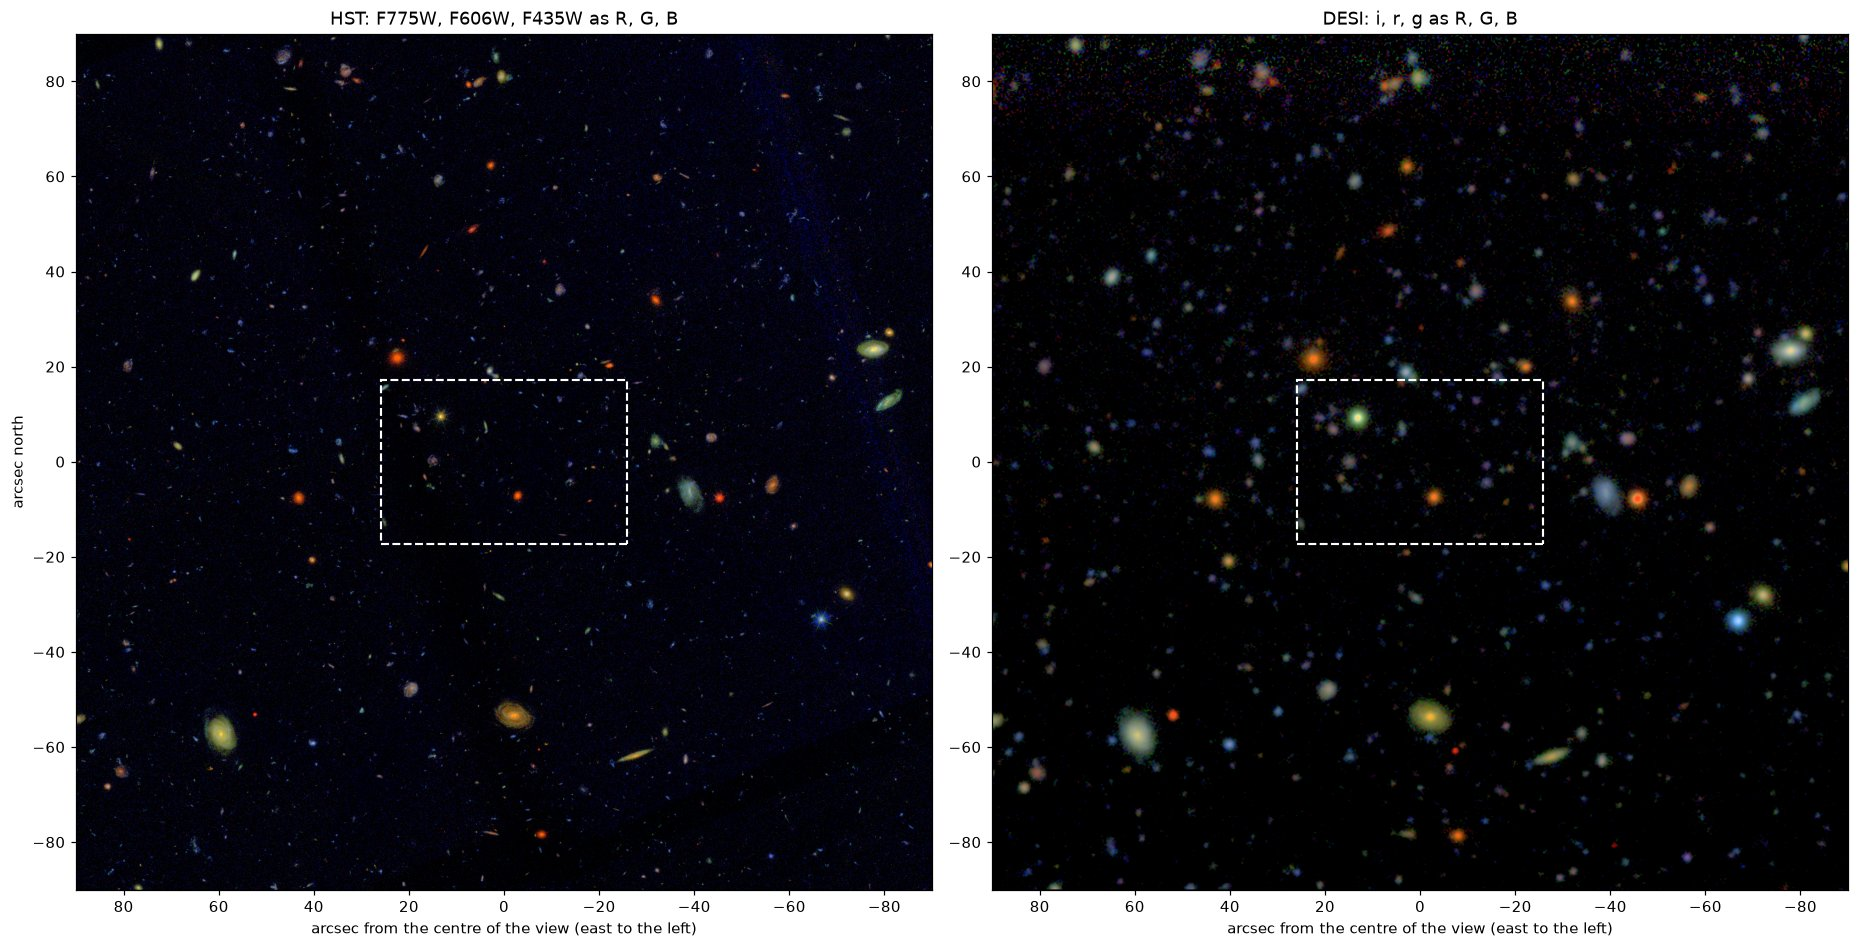

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8.4))
for ax, (rgb, title) in zip(axes, ((hst_rgb, "HST: F775W, F606W, F435W as R, G, B"), (desi_rgb, "DESI: i, r, g as R, G, B"))):
    ax.imshow(rgb, origin="lower", extent=(-half, half, -half, half))
    ax.add_patch(Rectangle((-width / 2, -height / 2), width, height, fill=False, ec="w", lw=1.4, ls="--"))
    ax.set_title(title); ax.set_xlabel("arcsec from the centre of the view (east to the left)"); ax.invert_xaxis()
axes[0].set_ylabel("arcsec north")
fig.tight_layout()

# Part 2 · What WCC sees: a g-r-i colour image, from HST and from DESI

The 52" x 35" frame at the centre of the view, simulated with the WCC `zwo:g`, `zwo:r` and `zwo:i` filters. Two inputs, each with three bands:

* **from the HST images**: F435W goes in as `zwo:g`, F606W as `zwo:r` and F775W as `zwo:i` (the closest HST bands; each image is taken to be in the WCC band it is simulated in);
* **from the DESI images**: g, r and i go in as `zwo:g`, `zwo:r` and `zwo:i`.

Each filter is one simulation with the exposure of the HST V-band image (about 1.5 h, a typical GOODS-South region) as a stack of equal frames, and the three are coloured with the recipe of Part 1.
The image itself goes into the simulation (`ImageComponent`), so the WCC image is the input image seen through the WCC PSF, pixels and noise: WCC cannot add detail that is not in the image that goes in.

In [7]:
N_FRAMES = 6                             # equal frames in the stack
T_EXP = gc.TYPICAL_EXPOSURE_S[FIELD]["f606w"]
BANDS = (("f435w", "g"), ("f606w", "r"), ("f775w", "i"))          # HST band, DESI band and WCC filter that go together
print(f"exposure {T_EXP:.0f} s = {T_EXP / 3600:.2f} h -> a stack of {N_FRAMES} x {T_EXP / N_FRAMES:.0f} s in each filter")

# the 52" x 35" frame is cut out of the 3' HST images of Part 1 (same pixels, no second download); DESI cutouts are fetched at their own pixel size
hst_crop = {hb: Cutout2D(hst_cut[hb][0], SkyCoord(RA, DEC, unit="deg"), (round(height / 0.030), round(width / 0.030)),
                         wcs=hst_cut[hb][1], mode="strict") for hb, _ in BANDS}
desi_crop = {db: lsm.fetch_ls_cutout(RA, DEC, 256 * 0.262, layer="ls-dr10", band=db, npix=256) for _, db in BANDS}

# the real images on the WCC pixel grid
hst_frame = {db: regrid(nanomaggies(hst_crop[hb].data, hst_cut[hb][2], 0.030), hst_crop[hb].wcs, frame.wcs, frame.shape) for hb, db in BANDS}
desi_frame = {db: regrid(desi_crop[db][0] / 0.262**2, desi_crop[db][1], frame.wcs, frame.shape) for _, db in BANDS}

exposure 5450 s = 1.51 h -> a stack of 6 x 908 s in each filter


## Simulate WCC in g, r and i

One call per filter and input: `exptime` is the total, `n_reads` the number of frames, so the simulator applies Poisson noise on source, sky and dark, read noise once per frame, and saturation
per frame. Gaia is switched off because the stars are already in the images. `ImageComponent` clips negative pixels to zero, which would turn the positive half of the image noise into frozen sky
signal, so only connected regions of detected light are kept (`mask_to_sources`).

In [8]:
def observe(component, sensorfilter, seed):
    f = simulate_field(RA, DEC, sensorfilter=sensorfilter, exptime=T_EXP, n_reads=N_FRAMES, shape=SHAPE, seed=seed,
                       extended_sources=[component], catalog=empty_catalog())
    nmgy = 10.0 ** (0.4 * (22.5 - REF_MAG)) * (f.image_e / T_EXP) / rate_for_ab(REF_MAG, sensorfilter)
    sb = nmgy / pix**2
    return sb - np.nanmedian(sb)

wcc_hst, wcc_desi = {}, {}
for k, (hb, db) in enumerate(BANDS):
    sensorfilter = f"zwo:{db}"
    wcc_hst[db] = observe(ImageComponent(hcm.mask_to_sources(hst_crop[hb].data), hst_crop[hb].wcs, hst_cut[hb][2]), sensorfilter, 1 + k)
    ls, ls_wcs = desi_crop[db]
    wcc_desi[db] = observe(ImageComponent(hcm.mask_to_sources(ls, smooth_sigma_px=0.7, dilate_px=1, min_area_px=6), ls_wcs, 22.5),
                           sensorfilter, 11 + k)
print("simulated:", ", ".join(f"WCC {db} from HST/DESI" for _, db in BANDS))

simulated: WCC g from HST/DESI, WCC r from HST/DESI, WCC i from HST/DESI


## The colour images and zooms on individual galaxies

Four colour images of the frame: the two real images and the two WCC mocks. The WCC images are smoothed lightly for display (sigma = 2 WCC pixels = 34 mas, below the ~50 mas WCC PSF)
because the noise of a single 1.5 h frame at the native 17 mas pixel would otherwise show as coloured speckle. The zooms use the three largest resolved galaxies among the brighter ones in the frame,
found from the Legacy Surveys Tractor catalog.

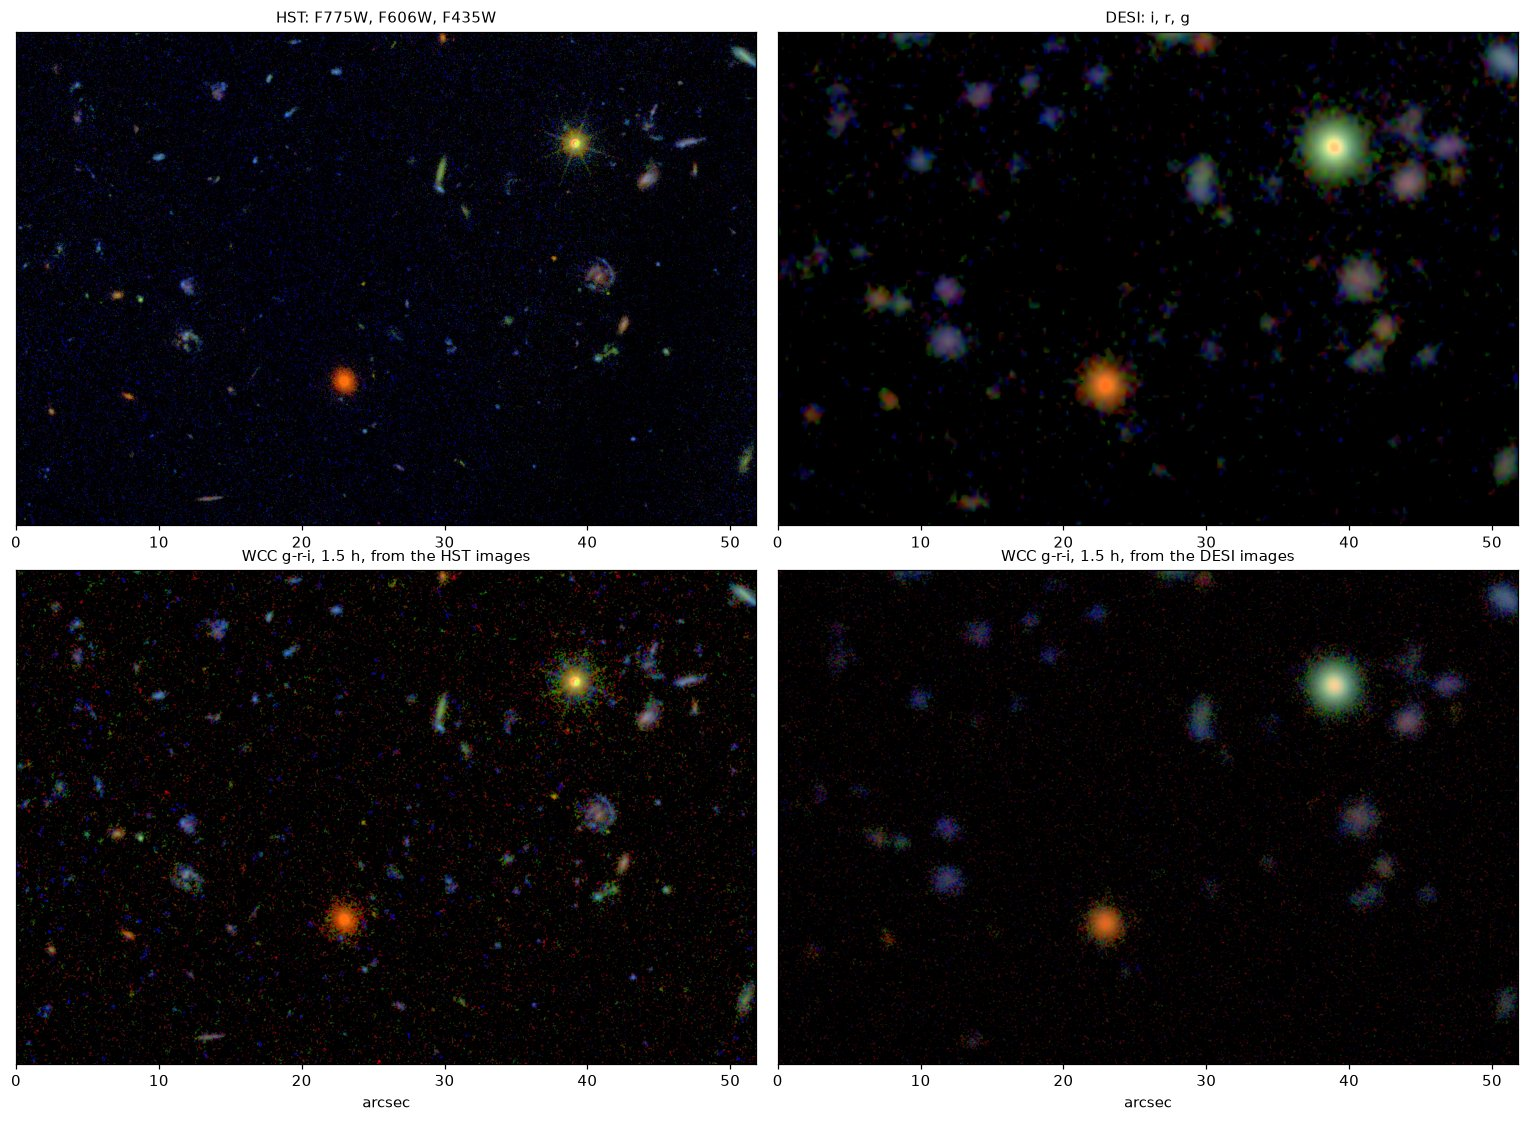

In [9]:
hst_frame_rgb = colour_image(hst_frame["i"], hst_frame["r"], hst_frame["g"], stretch_sigma=STRETCH_HST)
desi_frame_rgb = colour_image(desi_frame["i"], desi_frame["r"], desi_frame["g"], stretch_sigma=STRETCH_DESI)
smooth = lambda bands: {b: gaussian_filter(np.nan_to_num(a), 2.0) for b, a in bands.items()}
wcc_hst_rgb = colour_image(*(smooth(wcc_hst)[b] for b in "irg"), stretch_sigma=STRETCH_WCC_HST)
wcc_desi_rgb = colour_image(*(smooth(wcc_desi)[b] for b in "irg"), stretch_sigma=STRETCH_WCC_DESI)

T_LABEL = f"{T_EXP / 3600:.1f} h"
PANELS = [(hst_frame_rgb, "HST: F775W, F606W, F435W"), (desi_frame_rgb, "DESI: i, r, g"),
          (wcc_hst_rgb, f"WCC g-r-i, {T_LABEL}, from the HST images"), (wcc_desi_rgb, f"WCC g-r-i, {T_LABEL}, from the DESI images")]

fig, axes = plt.subplots(2, 2, figsize=(14, 2 * 7.0 * height / width + 0.8))
for k, (ax, (img, title)) in enumerate(zip(axes.flat, PANELS)):
    ax.imshow(img, origin="lower", extent=(0, width, 0, height))
    ax.set_title(title, fontsize=10); ax.set_yticks([])
    if k >= 2:
        ax.set_xlabel("arcsec")
fig.tight_layout()

338 Tractor rows; zooming on 3 galaxies (AB r = 22.8, 22.9, 23.0)


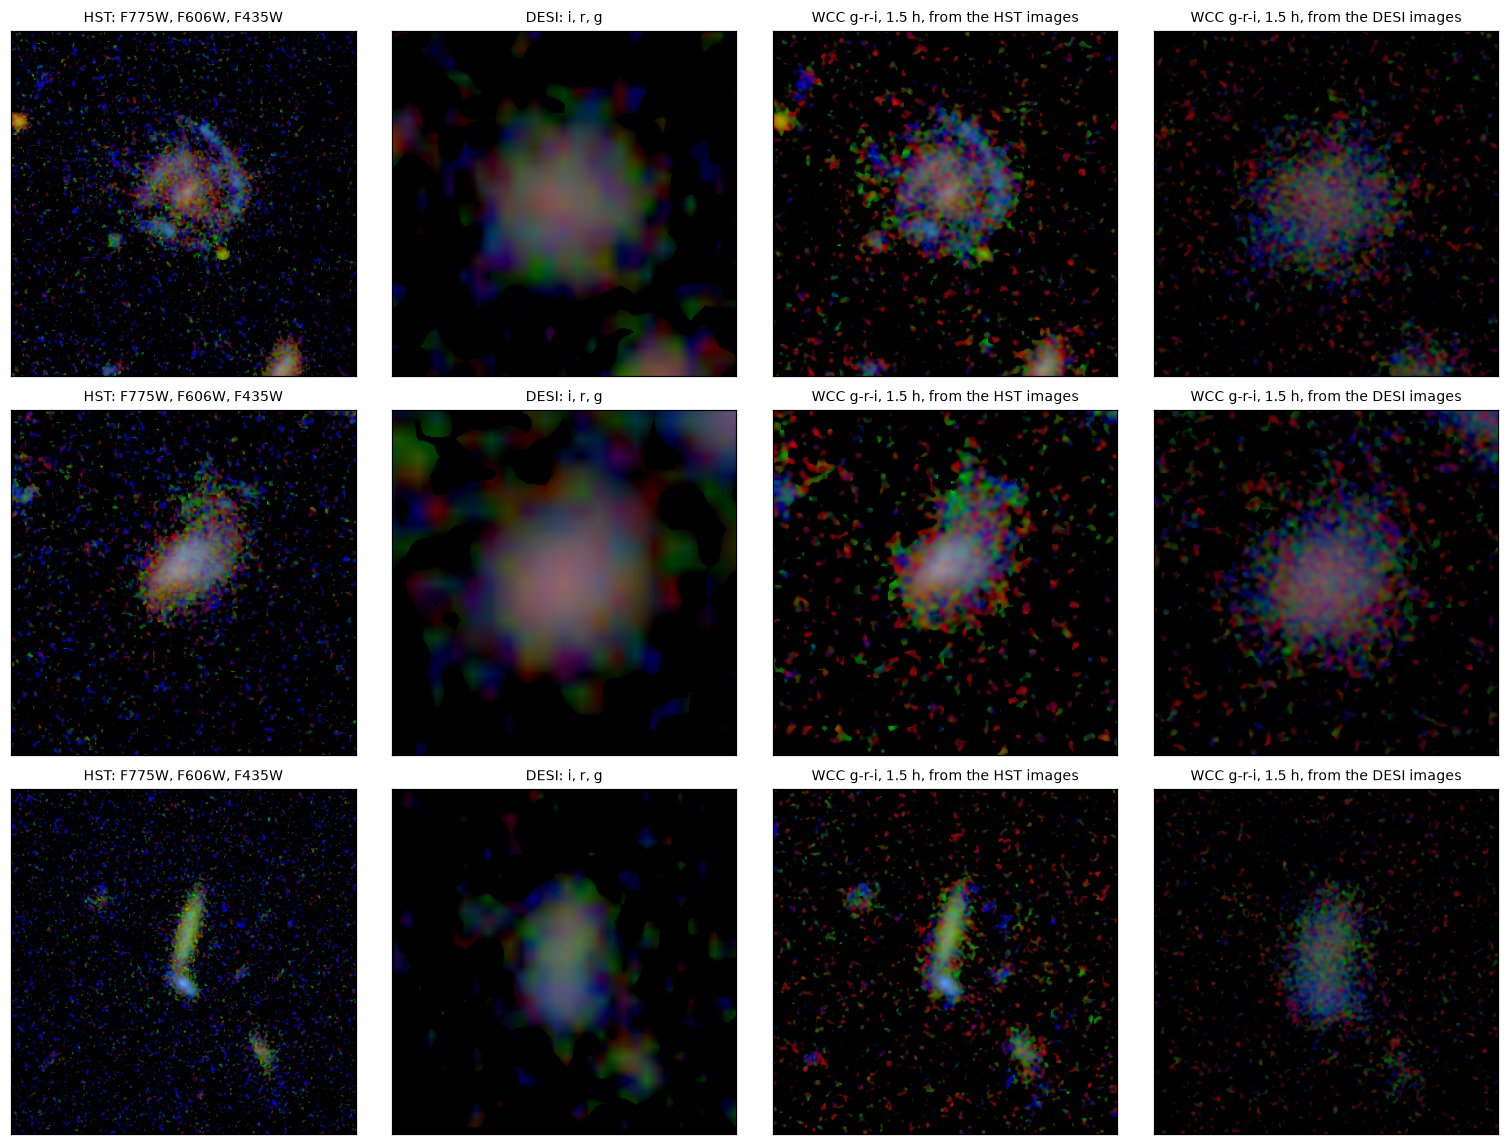

In [10]:
tractor = lsm.fetch_tractor(RA, DEC, half_diag + lsm.QUERY_MARGIN_ARCSEC, release="ls_dr10", cache_dir=CACHE)
_, truth = lsm.tractor_to_sersic(tractor, frame, SENSORFILTER)          # the resolved galaxies of the Tractor catalog, with positions and sizes
gx, gy = frame.wcs.world_to_pixel_values(truth["ra"], truth["dec"])
inside = (gx > 150) & (gx < nx - 150) & (gy > 150) & (gy < ny - 150)
cand = [i for i in np.argsort(truth["mag_ab_band"]) if inside[i] and truth["r_eff_arcsec"][i] > 0.4][:3]
print(f"{len(tractor)} Tractor rows; zooming on {len(cand)} galaxies (AB r = {', '.join(f'{truth['mag_ab_band'][i]:.1f}' for i in cand)})")

fig, axes = plt.subplots(len(cand), len(PANELS), figsize=(3.5 * len(PANELS), 3.5 * len(cand)))
for row, i in zip(np.atleast_2d(axes), cand):
    h = int(np.clip(4 * truth["r_eff_arcsec"][i], 2.5, 8.0) / pix)
    cx, cy = int(gx[i]), int(gy[i])
    sl = (slice(max(cy - h, 0), cy + h), slice(max(cx - h, 0), cx + h))
    for ax, (img, title) in zip(row, PANELS):
        ax.imshow(img[sl], origin="lower")
        ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
fig.tight_layout()